<a href="https://colab.research.google.com/github/ranimiftah12345678/ML_22_Ranimiftah/blob/main/JS06/JS06_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 33.2 MB/s eta 0:00:00


1a. Import Library

In [2]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

1b. Buat Kembali Fungsi Plotting

In [3]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
                levels=[-1, 0, 1], alpha=0.5,
                linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                    model.support_vectors_[:, 1],
                    s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

1c. Buat Data Dummy Non-Linier

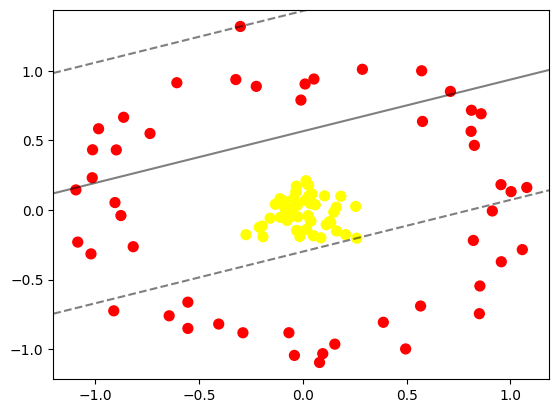

In [4]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

In [5]:
r = np.exp(-(X**2).sum(1))

In [6]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
          X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-0.2745079 , -0.17751473],
       [ 0.1485511 , -0.01561709],
       [-0.04561476,  0.0824943 ],
       [ 0.71092353,  0.85305085],
       [-0.03373809,  0.13061867],
       [-0.00956749,  0.79048196],
       [-0.19272894, -0.19255783],
       [ 0.03580949, -0.07593005],
       [ 1.00342313,  0.1321018 ],
       [-0.06749584, -0.88249893],
       [-0.87722308, -0.03972755],
       [ 0.04984393, -0.18498832],
       [ 0.57231588,  1.0013089 ],
       [ 0.05306249,  0.94195257],
       [-0.28919691, -0.88282555],
       [-0.01515245, -0.19053226],
       [-0.55452927, -0.66285958],
       [-0.73694965,  0.55036833],
       [ 0.85899059,  0.69212712],
       [-0.08887329,  0.03131943],
       [ 0.38759924, -0.80750552],
       [-0.03296137,  0.13036929],
       [-0.15823109, -0.05922327],
       [ 0.02772371,  0.17769309],
       [-0.19674128, -0.11566102],
       [-0.10875348, -0.05231748],
       [-0.04806184,  0.01393052],
       [-0.09438106,  0.06629759],
       [-0.055087  , -0.0287606 ],
       [ 0.04391281,  0.11457931],
       [ 0.11220307, -0.10563804],
       [ 0.49518063, -0.99901675],
       [-0.01357676, -0.15732391],
       [-0.55440232, -0.85164099],
       [-0.03168179,  0.17156572],
       [ 0.01793126, -0.13842714],
       [ 0.09561657, -1.03302872],
       [ 0.20583874, -0.176588  ],
       [ 0.16158189, -0.15071811],
       [ 0.01086279,  0.06967685],
       [ 0.82140189, -0.21879864],
       [-0.07640829, -0.07512326],
       [ 0.5672164 , -0.6903777 ],
       [-0.04101608, -1.04550509],
       [-0.40583782, -0.82007896],
       [ 0.05936976,  0.03777423],
       [ 0.15383917, -0.96457279],
       [ 0.95621943, -0.37215219],
       [ 0.16109921,  0.02025157],
       [-0.98484015,  0.58445182],
       [-0.60765635,  0.9154835 ],
       [ 1.07913299,  0.16184799],
       [-0.22474514,  0.88934941],
       [-0.86426489,  0.66697315],
       [-0.89949756,  0.43221942],
       [-0.1330903 ,  0.04143019],
       [-1.09424035,  0.14454431],
       [ 0.2542635 ,  0.02595964],
       [ 0.0291857 ,  0.10230786],
       [-0.02663418,  0.03542041],
       [ 0.85298815, -0.54645316],
       [-0.3015562 ,  1.31990312],
       [ 0.95469543,  0.18248595],
       [ 0.81060747,  0.56569909],
       [-0.90584354,  0.0536116 ],
       [ 0.02523966, -0.0401879 ],
       [ 0.57636023,  0.63688541],
       [-0.08729597,  0.0136246 ],
       [ 0.03861288,  0.05618629],
       [-0.21037856, -0.12414988],
       [ 0.01502378,  0.21076006],
       [-0.02460154, -0.04895874],
       [-0.91170753, -0.72505936],
       [ 0.25937102, -0.20260746],
       [-0.11027916,  0.08137824],
       [ 0.91294952, -0.00693892],
       [-0.81804073, -0.26387715],
       [ 0.28665771,  1.01194957],
       [ 0.08014118, -1.09648776],
       [ 0.10417687,  0.10200229],
       [ 0.01048517,  0.90622736],
       [ 0.18290024,  0.09917346],
       [ 0.82630337,  0.46496696],
       [-1.02154331, -0.31549977],
       [-0.06381639, -0.05008235],
       [ 0.13366092, -0.09034289],
       [-0.64470428, -0.7607752 ],
       [ 0.08620282, -0.19969591],
       [ 0.01927783,  0.18917078],
       [-1.01382935,  0.43313354],
       [ 0.03626464,  0.04614863],
       [ 0.8504711 , -0.74567241],
       [-1.01546827,  0.23220832],
       [ 0.03840828, -0.07957401],
       [-0.32333496,  0.93824631],
       [ 1.05753092, -0.28483881],
       [ 0.81226777,  0.71740364],
       [ 0.12766178, -0.08409476],
       [-0.03084559, -0.14655116],
       [-1.08536025, -0.2307292 ]]), y=array([1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1,
       0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1,
       1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0]))>

2. Fitting Model

In [7]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

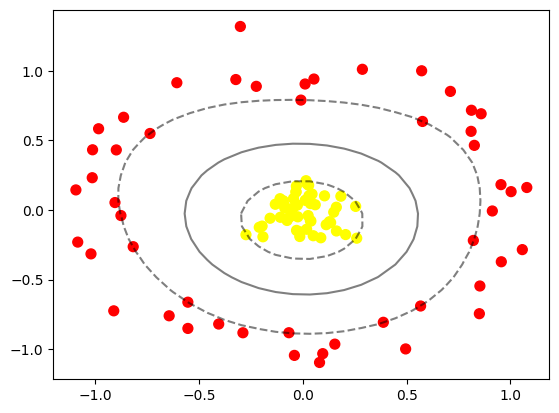

In [8]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')